In [1]:
import spacy
import wordcloud
nlp= spacy.load('en_core_web_sm')
import nltk
nltk.download('all')
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/abc.zip.
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/alpino.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_ru.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_rus to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |  

In [2]:
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize,sent_tokenize

In [3]:
#### Punctuation
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [4]:
#### Stopwords
stop= stopwords.words('english')
print(stop)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [5]:
len(stop)

198

In [7]:
#### Lemmatization
lemma= WordNetLemmatizer()
lemma.lemmatize('running',pos='v')

'run'

In [8]:
lemma.lemmatize('mixing',pos='v')

'mix'

In [11]:
lemma.lemmatize('better',pos='a')

'good'

In [12]:
#### Stemming
stem= PorterStemmer()
stem.stem('running')

'run'

In [13]:
stem.stem('beautiful')

'beauti'

In [15]:
##Tokenization
data='Data Science class started in July 2026. The classes are going well so far.'

In [16]:
words= word_tokenize(data)
print(words)

['Data', 'Science', 'class', 'started', 'in', 'July', '2026', '.', 'The', 'classes', 'are', 'going', 'well', 'so', 'far', '.']


In [17]:
sentence= sent_tokenize(data)
print(sentence)

['Data Science class started in July 2026.', 'The classes are going well so far.']


In [22]:
doc=nlp(data)
doc

Data Science class started in July 2026. The classes are going well so far.

In [31]:
for token in doc:
  print(token.text,token.pos_,spacy.explain(token.pos_),token.lemma_,
        token.is_stop,token.is_punct,token.is_digit,token.is_bracket,
        token.is_currency)

Data PROPN proper noun Data False False False False False
Science PROPN proper noun Science False False False False False
class NOUN noun class False False False False False
started VERB verb start False False False False False
in ADP adposition in True False False False False
July PROPN proper noun July False False False False False
2026 NUM numeral 2026 False False True False False
. PUNCT punctuation . False True False False False
The DET determiner the True False False False False
classes NOUN noun class False False False False False
are AUX auxiliary be True False False False False
going VERB verb go False False False False False
well ADV adverb well True False False False False
so ADV adverb so True False False False False
far ADV adverb far False False False False False
. PUNCT punctuation . False True False False False


Named Entity Recognition (NER)

In [34]:
doc=nlp(data)
doc

Data Science class started in July 2026. The classes are going well so far.

In [38]:
for token in doc.ents:
  print(token.text,token.label_,spacy.explain(token.label_))

July 2026 DATE Absolute or relative dates or periods


In [39]:
doc= nlp('The most widely acclaimed and awarded documentary about the war is 20 Days in Mariupol (2023), which won the Academy Award for Best Documentary Feature.')


In [42]:
for token in doc.ents:
  print(token,token.label_,spacy.explain(token.label_),token.start_char,token.end_char)

20 Days DATE Absolute or relative dates or periods 67 74
Mariupol GPE Countries, cities, states 78 86
2023 DATE Absolute or relative dates or periods 88 92
the Academy Award for Best Documentary Feature ORG Companies, agencies, institutions, etc. 105 151


In [43]:
spacy.displacy.render(doc,style='ent')

WordCloud

In [59]:
course= 'DataScience,The RProgramming, MySQL, AI, AI, Python, DataScience, DataAnalyst,PowerBI'

In [60]:
from wordcloud import WordCloud, STOPWORDS

In [61]:
stop_word=STOPWORDS
print(stop_word)

{'this', 'your', 'otherwise', 'she', 'should', 'at', 'after', "doesn't", 'herself', 'between', 'does', 'were', "you'd", 'get', 'the', 'under', 'was', "what's", "let's", 'whom', 'however', 'a', 'by', "can't", 'other', 'we', 'my', 'as', 'just', 'than', "when's", "where's", "shouldn't", "mustn't", "wouldn't", 'been', 'its', 'on', 'in', "he'd", "you've", "i'm", 'these', "we're", 'yourself', 'few', 'any', 'shall', "there's", 'but', 'www', "she'd", "i've", "we'll", 'have', 'he', "won't", 'me', 'both', 'him', 'http', 'therefore', 'yourselves', 'about', "how's", 'ought', "why's", 'their', 'nor', 'once', 'into', 'so', 'also', "hadn't", 'there', 'same', 'before', "shan't", 'would', 'do', 'having', 'most', 'only', 'too', "haven't", 'or', 'here', 'can', 'that', 'own', 'com', 'further', 'else', 'is', 'while', 'i', 'himself', 'ever', 'am', 'could', 'his', 'those', 'off', 'an', 'them', 'with', 'itself', "here's", 'during', 'how', 'to', 'until', 'for', "it's", 'through', 'no', "we'd", 'hence', 'cannot

In [62]:
len(stop_word)

192

In [79]:
stop= STOPWORDS.update(['MySQL','PowerBI'])

In [80]:
len(stop_word)

194

In [81]:
word_c=WordCloud(background_color='white',stopwords=stop).generate(course)
word_c

In [84]:
def plot_cloud(input):
  plt.figure(figsize=(12,10))
  plt.imshow(input)
  plt.axis('off')
  plt.savefig('course1.jpeg')

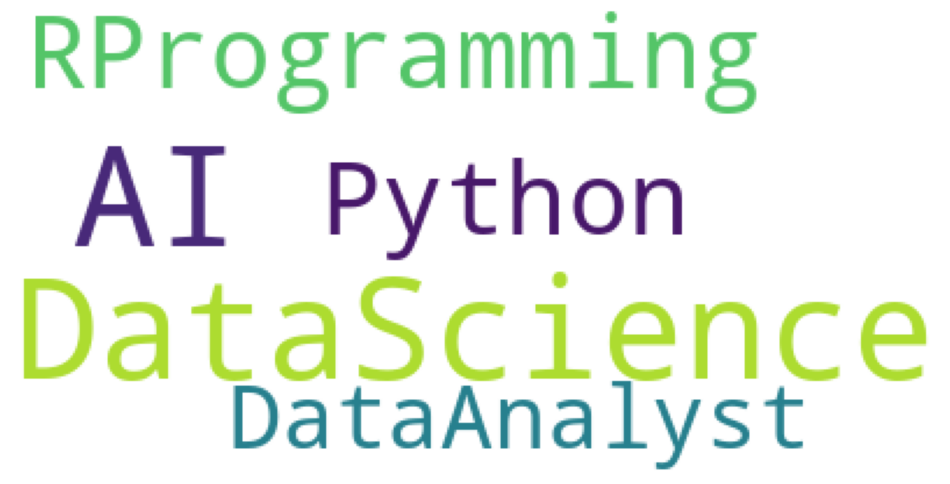

In [85]:
plot_cloud(word_c)

Data Cleaning

In [86]:
import re

In [88]:
dat='data cleaning*(**&**&^%^?><"|{})'

In [91]:
' '.join(re.findall('\w+',dat))

'data cleaning'

In [99]:
def data_clean(text):
  text1=  ' '.join(re.findall('\w+',text))
  doc= nlp(text1)
  cleaned_data= [token.lemma_ for token in doc if not token.is_stop and not token.is_punct
               and not token.is_bracket and not token.is_digit and not token.is_currency]
  return cleaned_data

In [100]:
data_clean('The data science class started in July 2026 (((*(*(*))))) kumar')

['data', 'science', 'class', 'start', 'July', 'kumar']

Word Embedding

In [101]:
#### CountVectorizer, TfIDFTransformer, TFIDFVectorizer
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer,TfidfTransformer

In [102]:
corpus=['this is the data science class with SL',
       'AI is the next class',
       'and this is third class',
       'and this is fourth class']

In [106]:
count= CountVectorizer(ngram_range=(1,1),analyzer=data_clean)
x= count.fit_transform(corpus)
x.toarray()

array([[0, 1, 1, 1, 0, 1],
       [1, 0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0, 0],
       [0, 0, 1, 0, 1, 0]])

In [107]:
print(count.get_feature_names_out())

['AI' 'SL' 'class' 'data' 'fourth' 'science']


In [111]:
tfidf= TfidfTransformer()
x_tfidf= tfidf.fit_transform(x)
x_tfidf.toarray()

array([[0.        , 0.55280532, 0.28847675, 0.55280532, 0.        ,
        0.55280532],
       [0.88654763, 0.        , 0.46263733, 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 1.        , 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.46263733, 0.        , 0.88654763,
        0.        ]])

In [109]:
tfidf_vect= TfidfVectorizer(ngram_range=(1,1),analyzer=data_clean)
x_tfidf= tfidf_vect.fit_transform(corpus)
x_tfidf.toarray()

array([[0.        , 0.55280532, 0.28847675, 0.55280532, 0.        ,
        0.55280532],
       [0.88654763, 0.        , 0.46263733, 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 1.        , 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.46263733, 0.        , 0.88654763,
        0.        ]])

In [117]:
df= pd.read_csv('/content/SMSSpamCollection',sep='\t',header=None,names=['label','msg'])

In [118]:
df.head()

,label,msg
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


<Axes: xlabel='label'>

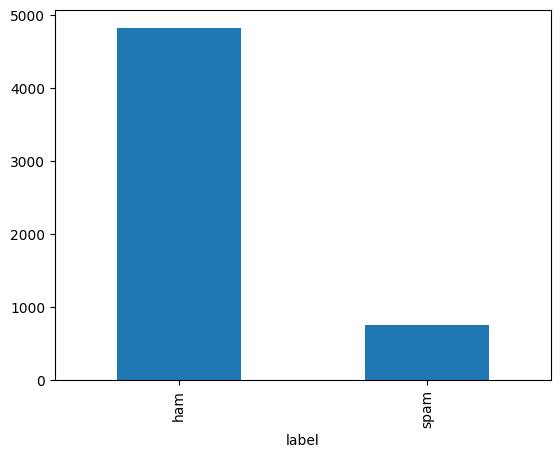

In [120]:
df.label.value_counts().plot(kind='bar')

In [121]:
df['len']= df['msg'].apply(len)

In [122]:
df.head()

,label,msg,len
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


array([<Axes: title={'center': 'ham'}>, <Axes: title={'center': 'spam'}>],
      dtype=object)

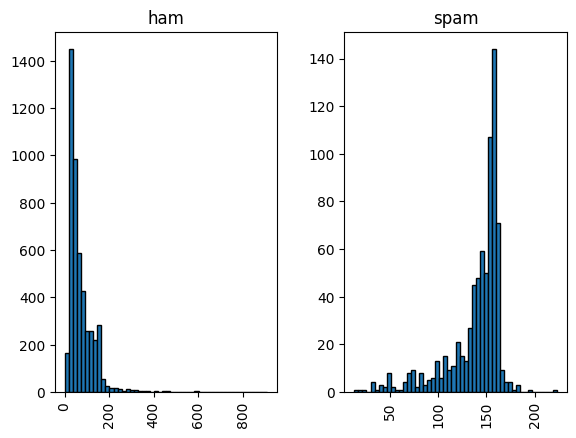

In [124]:
df.hist('len',by='label',bins=50,edgecolor='black')

In [126]:
df.len.describe()

,len
count,5572.000000
mean,80.489950
std,59.942907
min,2.000000
25%,36.000000
50%,62.000000
75%,122.000000
max,910.000000


In [131]:
df[df.len==910].loc[1085,'msg']

"For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later.."

In [133]:
df[df.len==200].loc[4418,'msg']

" says that he's quitting at least5times a day so i wudn't take much notice of that. Nah, she didn't mind. Are you gonna see him again? Do you want to come to taunton tonight? U can tell me all about !"

In [134]:
df.head()

,label,msg,len
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [135]:
tfidf= TfidfVectorizer(ngram_range=(1,1),analyzer=data_clean)
x_tfidf= tfidf.fit_transform(df['msg'])
x_tfidf.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [136]:
x_tfidf.shape

(5572, 8175)

In [137]:
from sklearn.ensemble import RandomForestClassifier
rand_for= RandomForestClassifier(n_estimators=100)
rand_for.fit(x_tfidf,df['label'])

RandomForestClassifier()

In [138]:
y_pred= rand_for.predict(x_tfidf)

In [139]:
from sklearn.metrics import accuracy_score
accuracy_score(df['label'],y_pred)

1.0

In [140]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(df['msg'],df['label'],train_size=0.8,random_state=100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(4457,)
(1115,)
(4457,)
(1115,)


In [141]:
from sklearn.pipeline import Pipeline

In [142]:
pipeline= Pipeline([('tfidf',TfidfVectorizer(analyzer=data_clean)),
                    ('classifier',RandomForestClassifier(n_estimators=100))])
pipeline.fit(x_train,y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer=<function data_clean at 0x7ed7fbcc6660>)),
                ('classifier', RandomForestClassifier())])

In [143]:
y_pred= pipeline.predict(x_test)
accuracy_score(y_test,y_pred)

0.9775784753363229

In [144]:
pipeline.predict(['U dun say so early hor... U c already then say...'])

array(['ham'], dtype=object)

In [145]:
pipeline.predict(['Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030'])

array(['spam'], dtype=object)